# Lecture 5 : Static Files & Boostrap

# Dr. Changjiiang Zhang
# CS, WKU
# Spring 2025

## 1. Introduction

Bootstrap is a powerful front-end framework for faster and easier web development. It includes **HTML and CSS based design templates** for creating common user interface components like forms, buttons, navigations, dropdowns, alerts, modals, tabs, accordions, carousels, tooltips, and so on.

Bootstrap gives you ability to create flexible and responsive web layouts with much less efforts.

Bootstrap was originally created by a designer and a developer at Twitter in mid-2010. Before being an open-sourced framework, Bootstrap was known as Twitter Blueprint.

### 1.1 What You Can Do with Bootstrap
There are lot more things you can do with Bootstrap.
- You can easily create responsive websites.
- You can quickly create multi-column layout with pre-defined classes.
- You can quickly create different types of form layouts.
- You can quickly create different variation of navigation bar.
- You can easily create components like accordions, modals, etc. without writing any JS code.
- You can easily create dynamic tabs to manage large amount of content.
- You can easily create tooltips and popovers to show hint text.
- You can easily create carousel or image slider to showcase your content.
- You can quickly create different types of alert boxes.
The list does not end here, there are many other interesting things that you can do with Bootstrap. You will learn about all of them in detail in upcoming chapters.

### 1.2 Advantages of Using Bootstrap

Here are some advantages why one should opt for Bootstrap framework:

- Save lots of time — You can save lots of time and efforts using the Bootstrap predefined design templates and classes and concentrate on other development work.
- Responsive features — Using Bootstrap you can easily create responsive websites that appear more appropriately on different devices and screen resolutions without any change in markup.
- Consistent design — All Bootstrap components share the same design templates and styles through a central library, so the design and layout of your web pages will be consistent.
- Easy to use — Bootstrap is very easy to use. Anybody with the basic working knowledge of HTML, CSS and JavaScript can start development with Bootstrap.
- Compatible with browsers — Bootstrap is created with modern web browsers in mind and it is compatible with all modern browsers such as Chrome, Firefox, Safari, Internet Explorer, etc.
- Open Source — And the best part is, it is completely free to download and use.

Before start the Boostrap, we introduce django static files as we are going to import Bootstrap as static files.

## 2 Django Static Files

Today, websites have become much more interactive than ever. They contain tons of CSS and JavaScript Code to make our experience smoother.

There are lots of graphics involved on websites too. We can state that there are multiple files on a webpage.
Important point is that none of these files can be modified by the server. It means these files are transmitted as it is, without any modification.

### 2.1 Static Files
Static files are those files which can not be processed, generated or modified by the server. Images, JavaScript files, etc are types of content or static files. Static files contain all kinds of file types – from .mpeg, .jpeg to .pdf, etc.

There is a simple concept of working with static files. When a user requests for a webpage, the server will generate the HTML. Then the server will **collect all the corresponding static files** related to that page. Lastly, this whole data is served.

### 2.2 Benefits of Static Files
 - They are static: These files don't change until the developer replace them with a new one. Thus the server just fethces them from the disk, taking a minimum amount of time.
 - Static files are energy efficient: Static files are fetched from the disk when required. They require no processing which saves the processing overhead and website response becomes fast.

### 2.3 Template Inheritance
Let’s understand one more important topic, i.e. Template Inheritance. Developers use it more efficiently with **template inheritance** method and it is one of Django’s key features.

The basic concept is that: We define the common parts of a webpage, such as navigation bars and About section. All these parts are essentially HTML and some static files. Majority of webpages will contain similar sections.

The problem is there are lots of webpages, if we want to modify one section, then we have to change the code on every page which leads to chaos. Django templating solves this problem by inheritance. We can define a base template, which contains the nav bars and About section, for example. Then, inherit this page and just add the unique part in other webpages.

**Defining Templates**

Now, we do practice the usage of template inheritance. First define a base.html as follows:

In [ ]:
<!DOCTYPE html>
<html>
<head>
    <title>HomePage</title>
</head>
<body>
<center>
    <h1>WKU News Application</h1>
    
{% block body_block %}
<h1>Welcome to the Homepage</h1>
<h2> we are in the block of home page</h2>
{% endblock %}

</center>
</body>
</html>

In this code, you must be noticing that we used some new template tags. 
- The tag, ``{% block body_block %}`` is used for template inheritance. We are actually replacing this section of code between ``{% block body_block %} … {% endblock %}``. 
- The name ``body_block`` can be of your choice. There can be multiple blocks of this type. It’s up to you to change them or use them as it is.

Now, create another template ``others.html``.


In [ ]:
{% extends "base.html" %}

{% block body_block %}
    <h2> we are in the block of others page</h2>
{% endblock %}

Here, we used a new tag at the beginning. ``{% extends "base.html" %}`` is clear in itself. 
This tag will inform Django to add ``base.html`` code in ``others.html``. After that we used ``{% block body_block %} …. {% endblock %}``, which contains this page’s unique content. This block is swapped with the block in ``base.html``.

Modify ``wkunews/urls.py`` and ``wkunews/views.py`` accordingly to use the new templates.

In [ ]:
# urls.py file
from django.urls import path

from . import views

urlpatterns = [
    path('', views.index),
    path('login',views.login),
    path('success', views.success),
    path('home', views.home),
    path('others', views.others)
]


In [ ]:
# add the following two views
def home(request):
    return render(request, 'base.html')
def others(request):
    return render(request,'others.html')

Then, visit http://127.0.0.1:8000/wkunews/home and http://127.0.0.1:8000/wkunews/others to see the pages.

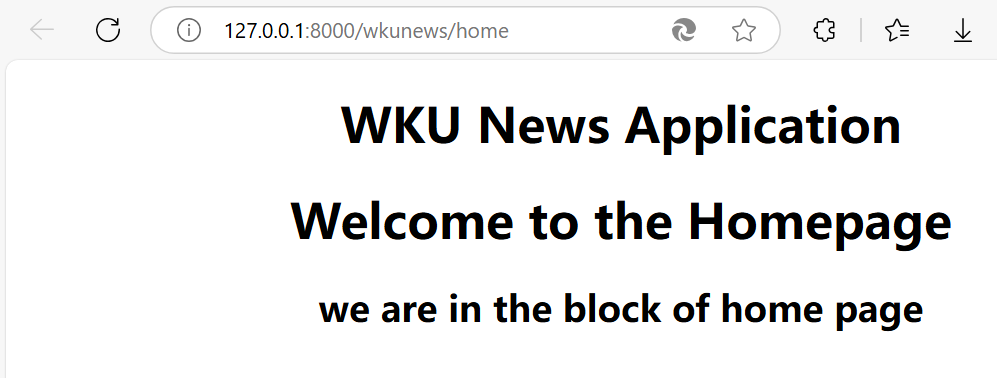
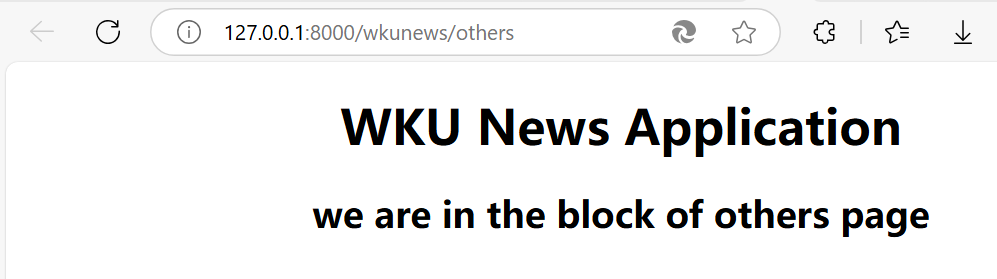

That’s how we perform template inheritance.
Remember, there can be multiple blocks in a single template.
Now, we will add some static files so that our page looks more attractive. We will be modifying our ``settings.py`` a little bit.

### 2.4 Manage Static Files

Django provides us with built-in static file handler. It’s a very simple concept and requires some modification in ``settings.py``. Check the list of ``INSTALLED_APPLICATIONS`` in settings.py file.

``INSTALLED_APPS = [
    'django.contrib.admin',
    'django.contrib.auth',
    'django.contrib.contenttypes',
    'django.contrib.sessions',
    'django.contrib.messages',
    'django.contrib.staticfiles',
    'wkunews'
]``

- Application "django.contrib.staticfiles" is the built-in static file handler. Make sure you have this line included in your ``INSTALLED_APPS``.

Also, we have ``STATIC_URL`` variable in the last section of the page:

In [ ]:
# Static files (CSS, JavaScript, Images)
# https://docs.djangoproject.com/en/2.2/howto/static-files/

STATIC_URL = '/static/'

1. ``STATIC_URL``: This is the base URL for all static files of your project. 
2. ``STATIC_ROOT``. This setting contains the address of the folder where we will be storing static files. When we execute the ``collectstatic command``, the Django will store our files in this directory.
3. The last is a list of directories – ``STATICFILES_DIRS``. This list has file-paths of the folders where we store our static files. When we execute the collectstatic command, Django will look for static files in these directories. Then it will save them in our ``STATIC_ROOT`` folder (for deployment).

Add the following codes in the setting file:

In [ ]:
# Static files (CSS, JavaScript, Images)
# https://docs.djangoproject.com/en/2.2/howto/static-files/

# URL prefix for static files
STATIC_URL = '/static/'

# Absolute path to the directory in which static files should be collected
STATIC_ROOT = os.path.join(BASE_DIR, 'root')

# Additional locations for static files (optional)
STATICFILES_DIRS = [os.path.join(BASE_DIR,'static'),]


Then, under debug mode, Django will check all the ``static`` folders of each application and the folder lists specified in ``STATICFILES_DIRS`` to load static files.
- Create a folder named ``static`` under the project directory.

### 2.5 Edit Template for Static Files

Modify the ``others.html`` as follows to include static files:

In [ ]:
{% extends "base.html" %}
{% block body_block %}
{% load static %}
    <h2> This is the demo of static files</h2>
    <img src="{% static 'wkunews/img/wku1.jpg' %}">
    <br>
    <img src="{% static 'wku2.jpg' %}">
    <h2> we are in the block of others page</h2>

{% endblock %}

- ``{% load static %}`` tag will inform Django that there are static files in this template. Django will then check for the related static files. Then sends them together with the HTML code.
- Download an image of uic, rename it to ``wku1.jpeg``and put it under the ``static/wkunews/img`` folder. In app folder (uicnews), create a subfoloder ``static`` and download second image of uic named ``wku2.jpeg`` and put it under the ``static`` folder.
- We gave the ``src`` of the image tag. The source of image tag is a Django tag. Here we used ``static`` keyword and the path to the image. The path is not specified from the root directory. The ``STATIC_URL`` value is automatically added to the source of the image file (prefix), even though it is coming from a different directory altogether.


Then, visit others page http://127.0.0.1:8000/wkunews/others and you will see the image in your page.

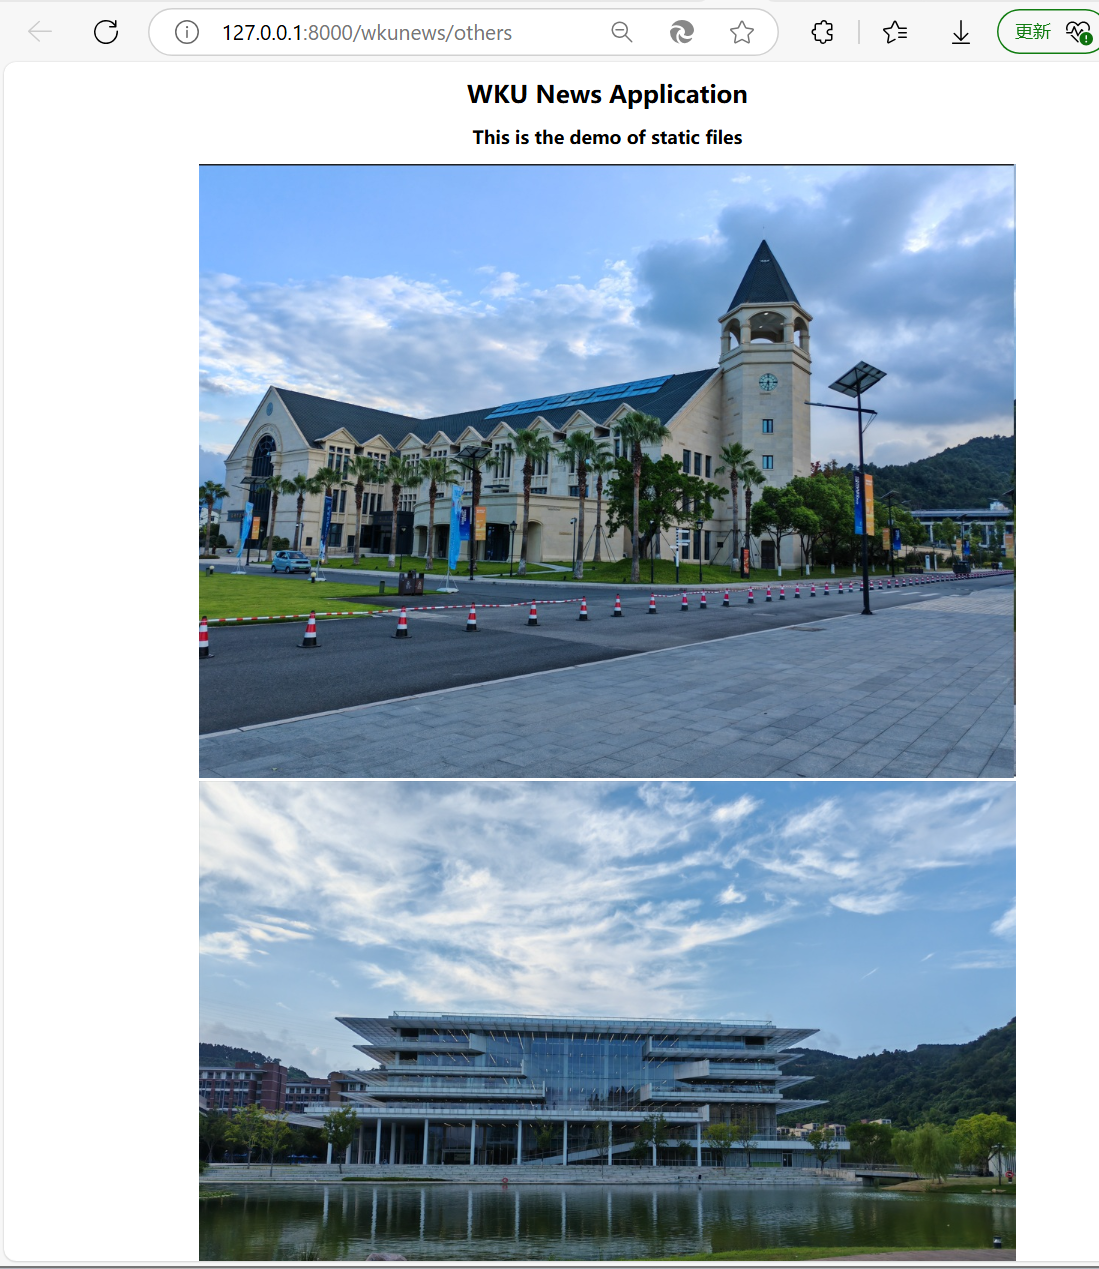

## 3. Bootstrap in Django

It is very easy to use Bootstrap in Django. Since Bootstrap is a front-end framework, it completely consists of CSS & JavaScript files. These files are considered **static** on the server side.

To use Bootstrap in the Django project, there are two ways:

### 3.1 Bootstrap CDN
Add Bootstrap in your project is via Bootstrap CDN (content dilivery network). Remember that, this method will require internet access for every request.

The concept is; in the <link> tag of HTML, we provide the URL of Bootstrap files. These files are then fetched online when requested from Bootstrap CDN. To get the URL links, check its official website.

You can just copy the given <link> tags. The CSS will add pre-compiled CSS in your HTML files.

### 3.2 Downloading Boostrap

This option allows for offline testing of templates. So, as we know that Bootstrap is a collection of JavaScript and CSS files and we can download the same from its website.  

**Step1:** You can download Bootstrap from its official site – [Getbootstrap](https://getbootstrap.com/docs/4.4/getting-started/download/). You will get a .zip file there. Extract that zip file and you will get a folder.


``bootstrap-4.4.1-dist
      css/
      js/
``

As we can see, there are two directories in Bootstrap, namely, ``css`` and ``js``.

- The ``css`` directory contains multiple CSS files. Some of these files may require different dependencies.
- The ``js`` directory contains multiple JavaScript files. These JavaScript files will not work without dependencies like jQuery and Popper. These are JavaScript libraries that support Bootstrap JS framework.


**Step2**: Go to your static directory under the project folder and create a new directory ``bootstrap``. There, copy the above two folders.

``
 HelloWorld
     db.sqlite3
     HelloWorld/
     manage.py
     static
         boostrap
             css/
             js/
     templates/
     wkunews/
``

**Step3**: Download ``jquery.js`` and ``popper.js``. Just go to the official website, enter download page and copy all the contents into the new file.
- [jquery download](https://jquery.com/download/), create a folder "jquery" and save all the content with name "jquery-3.5.1.js".
- [popper download](https://unpkg.com/popper.js@1.14.4/dist/umd/popper.js), create a folder "popper" and save all the content with name "popper-1.14.4.js".

``
 HelloWorld
     db.sqlite3
     HelloWorld/
     manage.py
     static
         boostrap
             css/
             js/
         jquery
             jquery-3.5.1.js
         popper
             popper-1.14.4.js
         wkunews
             img
     templates/
     wkunews/
``

We have uploaded static files for this project on iSpace. You can download from there and unzip it.


### 3.3 Adding Bootstrap

Now, lets create a template called ``header.html`` which will define the nagivation bar of the web pages.

In [ ]:
<nav class="navbar navbar-expand-lg navbar-light bg-light">
  <div class="container">

    <div>
      <ul class="nav">
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/home">Home</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/login">Login</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/register">Register</a>
        </li>
         <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/success">NewsList</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/others">Others</a>
        </li>

      </ul>
    </div>
  </div>
</nav>

In the ``header.html``, we define the navigation bar using the ``<nav>`` tag. The styles are specified by ``class`` attribute. Check the classes provide by bootstrap in their [official document](https://getbootstrap.com/docs/4.4/components/navbar/), which contains the code examples and the appearance.

Modify the template of ``base.html`` to include the header.

In [ ]:
{% load static %}

<!DOCTYPE html>
<html>
<head>
    <meta charset="utf-8">
    <title>HomePage</title>
    <!-- include the css file of bootstrap -->
    <link rel="stylesheet" href="{% static 'bootstrap/css/bootstrap.min.css' %}">
</head>
<body>
    <!-- include the navigation bar -->
    {% include "header.html" %}
    <center>
    <h1>WKU News Application</h1>
    
        {% block body_block %}
            <h1>Welcome to the Homepage</h1>
            <h2> we are in the block of home page</h2>
        {% endblock %}

    <!-- include jquery.js and popper.js -->
    <script src="{% static 'jquery/jquery-3.5.1.js' %}"></script>
    <script src="{% static 'popper/popper-1.14.4.js' %}"></script>    
    <!-- import bootstrap js -->
    <script src="{% static 'bootstrap/js/bootstrap.min.js' %}"></script>
</center>
</body>
</html>

- ``<link>`` tag is used to add CSS file from Bootstrap and "bootstrap.min.css" is imported as static file.
- ``{% include "header.html"%}``: import the header html content here.
- ``<script>`` tag is used to import js files.

Now, start your server or refresh the web browswer and visit the home page. You will see the navigation bar.

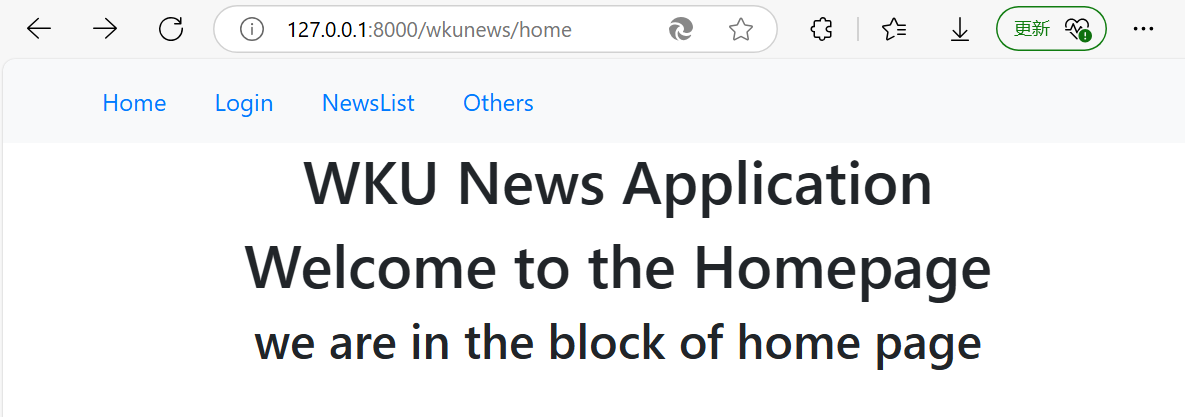

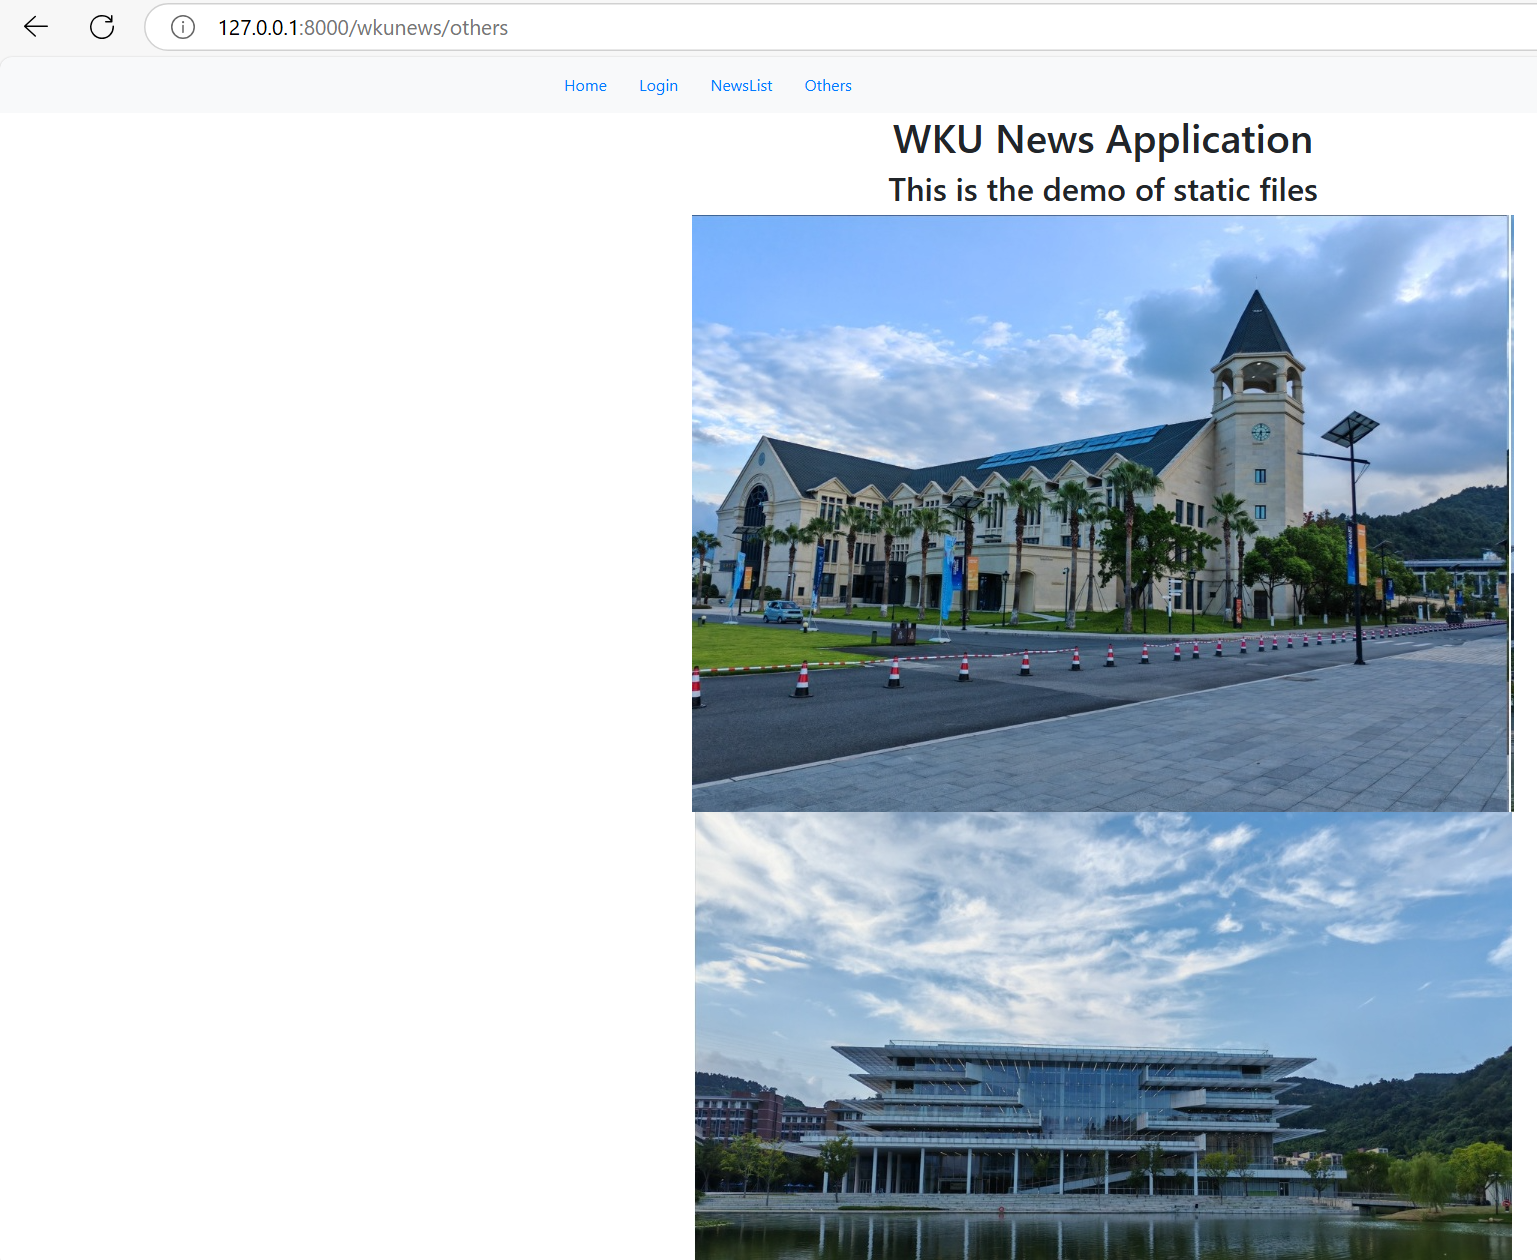

### 4 Bootstrap Examples

There are many tutorials about Bootstrap, you can refer to this [tutorial](https://www.tutorialrepublic.com/twitter-bootstrap-tutorial/) to explore all the features of the Bootstrap framework, starting with the basics, such as grid system, typography styling mechanism, form styling methods, as well as, techniques of styling common user interface elements like tables, lists, images, etc.

Also, you are suggested to check the official documents of [Bootstrap4](https://getbootstrap.com/docs/4.4/getting-started/introduction/) as it contains the comprehensive examples and usage guidlines for different components and features.

Next, I will show you the example of styling ``login`` page and ``wkunews`` page using Bootstrap.

#### 4.1 Login Page

Check the [form](https://getbootstrap.com/docs/4.4/components/forms/) document for examples and usage guidelines for form control styles, layout options, and custom components for creating a wide variety of forms.  

update ``login.html`` as folllows:

In [ ]:
{% extends "base.html" %}
{% block body_block %}
<div class="container">
    <h2>Login</h2>
    <form method="post">
        <div class="form-group">
            {% if message %}
                <div style="color:red" >{{ message }} Please try again!</div>
            {% endif %}
            {% csrf_token %}
            {{ form.as_p }}
        </div>
    <button type="submit" class="btn btn-primary">Login</button>
     
    </form>
</div>

{% endblock %}

The changes are:
- Login page inherits the base page and therefore will have the navigation bar included and bootstrap included.
- ``<div class="container">``: container class is a responsive, fixed-width container.
- ``<div class="form-group">``: bootsrap form style class.
- ``<button type="submit" class="btn btn-primary">``: bootstrap buttion style class. There are many button styles, refer to [button styles](https://getbootstrap.com/docs/4.4/components/buttons/) for examples.

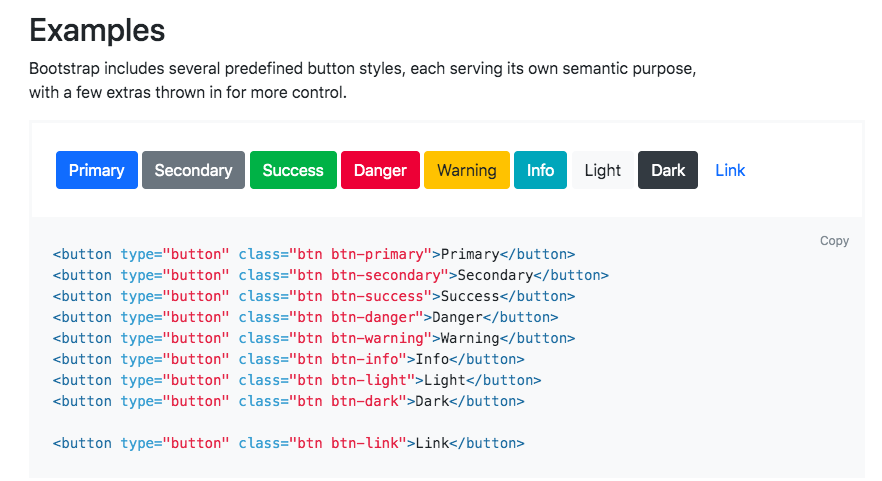


Now, start your server and visit the login page to check the result:

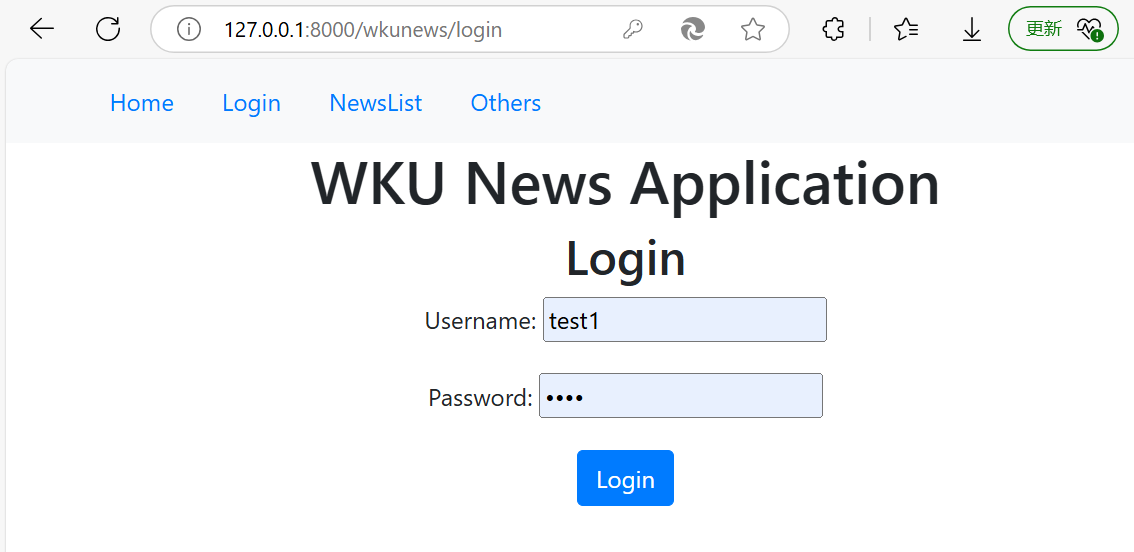

#### 4.2 Newslist Page

**Step1:** Design the layout using Bootstrap's grid system. 
- Bootstrap’s grid system uses a series of containers, rows, and columns to layout and align content. Refer to [grid system](https://getbootstrap.com/docs/4.4/layout/grid/) document for details.

In the following example, the page is designed to contain two columns. Suppose one column contains the information of current date and user and second column contains the list of news.

Initially, we should have the following code in ``success.html``:

In [ ]:
{% extends "base.html" %}
{% block body_block %}
    <div class="container-fluid">
      <div class="row">
            <div class="col-3"> 
            </div>
            <div class="col-9">
            </div>
        </div>
    </div>
{% endblock %}

In this code, we define a container (``container-fluid``), which provides a means to center and horizontally pad your site’s contents.

The grid is one row and two colums. The total number of columns of the grid system is 12 and we can specify the number of columns in the class attribute.

**Step2:** Design the content of each column. 
- For column one, I will use a list to show the information.
- For column two, I will use a table to show the wku news information.

Then, we can add the code for the two columns:

In [ ]:
{% extends "base.html" %}
{% block body_block %}
<div class="container-fluid">
  <div class="row">
    <div class="col-3"> 
      <ul class="list-group">
        <li class="list-group-item active"> WKU News List</li>
        <li class="list-group-item">Hello, testuser!</li>
        <li class="list-group-item">{{date}}</li>
      </ul>
    </div>
    <div class="col-9">
      <div class="table-responsive"> 
        <table class="table table-bordered table-striped table-hover"> 
          <thead> 
            <tr> 
              <th>ID</th>
              <th>Title</th>
              <th>Content</th>
              <th>Date</th>
              <th>Publisher</th>
              <th>Action</th>
            </tr> 
         </thead> 
         <tbody> 
         </tbody>
         </table>
      </div>
    </div>
</div>
{% endblock %}

- For list, we use ``<ul class="list-group">`` and ``<li>`` tag. 
- For table, we use ``<table>``, ``<td>``, ``<th>``, etc. tags. Check the [table document](https://getbootstrap.com/docs/4.4/content/tables/) for detail.

**Step3**: Finnaly, use the ``{% for %}`` and ``{% endfor%}`` to traverse the news variable and display the news information in the table.

Modify the view of success in ``uicnews/views.py`` as follows:

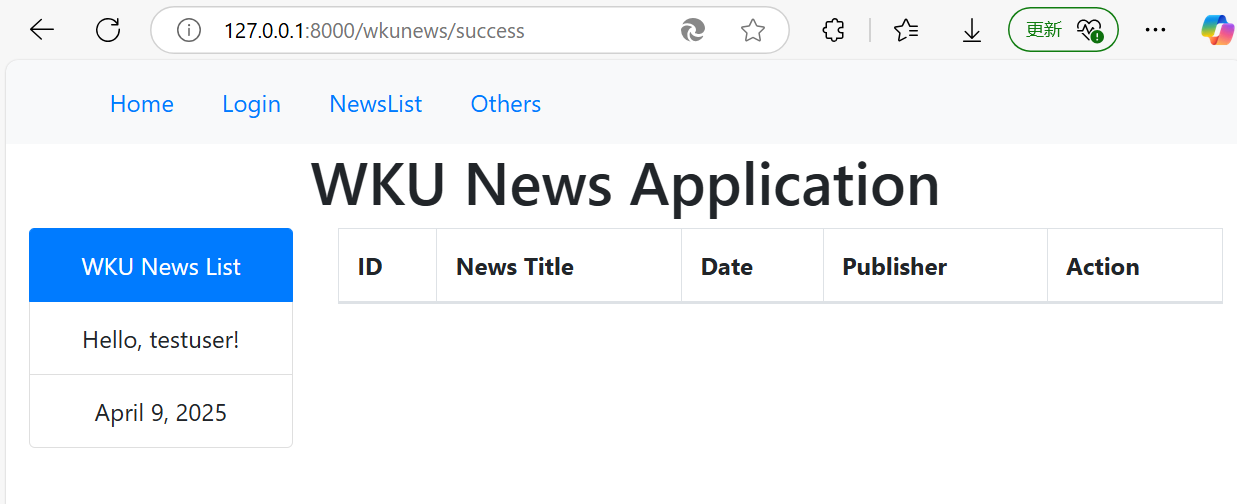

In [ ]:
def success(request):
    newslist=[]
    newslist.append([1,'CPS 3440 Quiz finished','2025-3-1','Rui'])
    newslist.append([2,'CPS 3962 Assignment released','2025-3-4','Qian'])
    newslist.append([3,'CPS 3962 Project Released','2025-3-7','Changjiang'])
    newslist.append([4,'CPS 3440 Quiz Grade Released','2025-3-10','Jie'])
    today = datetime.datetime.now().date()
    return render(request,"success.html",{"newslist":newslist,"date":today})

Modify the ``success.html`` as follows:

In [ ]:
{% extends "base.html" %}
{% block body_block %}
<div class="container-fluid">
  <div class="row">
    <div class="col-3"> 
      <ul class="list-group">
       <li class="list-group-item active"> WKU News List</li>
       <li class="list-group-item">Hello, testuser!</li>
       <li class="list-group-item">{{date}}</li>
      </ul>
    </div>
    <div class="col-9">
      <div class="table-responsive"> 
       <table class="table table-bordered table-striped table-hover">  
        <thead> 
         <tr> 
          <th>ID</th>
          <th>Title</th>
          <th>Content</th>
          <th>Date</th>
          <th>Publisher</th>
          <th>Action</th>
         </tr> 
        </thead> 
        <tbody> 
         {% for news in newslist %}
          <tr>
          {% for item in news%}
           <td>{{item}}</td>
          {% endfor%}
           <td>
            <button type="button" class="btn btn-primary btn-xs ">Read</button>
            <button type="button" class="btn btn-success btn-xs ">Hide</button>
            <button type="button" class="btn btn-danger btn-xs ">Delete</button>
           </td>
          </tr>               
        {% endfor %}
        </tbody>
      </table>
    </div>
   </div>
</div>
{% endblock %}

Now, start your server and visit the success page, you will see the following page:
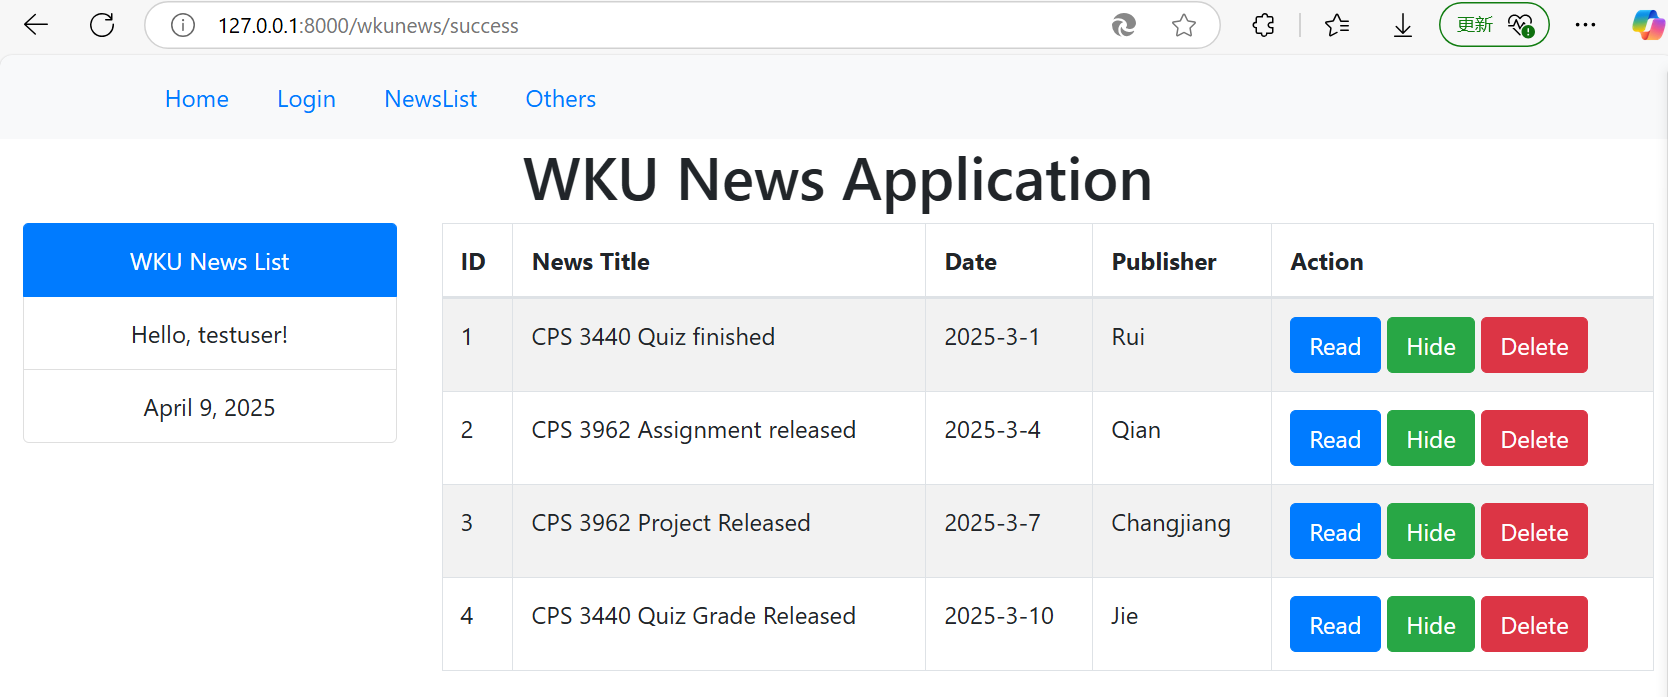

Exercise:
    If we want to pass username from login page to success page, what should you do?

Solution:
Modify login and success functions in views.py as follows:

In [ ]:
def login(request):
    if request.method == 'POST':
        username = ''
        passwd = ''
        message = ''
        form = LoginForm(request.POST or None)
        if form.is_valid():
            username = form.cleaned_data.get("username")
            passwd = form.cleaned_data.get("password")
            try:
                userinfo = user.objects.get(username=username)
                if userinfo.password == passwd:
                    request.session['username'] = username
                    
                    return HttpResponseRedirect('success')
                else:
                    message = 'Incorrect Password!'
            except:
                message = 'User not exist!'
            return render(request,'login.html',{'form':form, 'message':message}) 
    else:
        form = LoginForm()
    return render(request, 'login.html', {'form':form})

In [ ]:
def success(request):
    newslist=[]
    newslist.append([1,'CPS 3440 Quiz finished','test1',  'Rui', '2025-3-1'])
    newslist.append([2,'CPS 3962 Assignment released','test2', 'Qian', '2025-3-4'])
    newslist.append([3,'CPS 3962 Project Released','test3', 'John', '2025-3-7'])
    newslist.append([4,'CPS 3440 Quiz Grade Released','test4', 'Jie', '2025-3-10'])

    today = datetime.datetime.now().date()
    username = request.session['username']
    return render(request,"success.html",{"newslist":newslist,"date":today, "username":username})

Modify the success.html as follows:
(Here, newslist is passed as a list of lists, a 2d list)

In [ ]:
{% extends "base.html" %}
{% block body_block %}
<div class="container-fluid">
  <div class="row">
    <div class="col-3"> 
      <ul class="list-group">
       <li class="list-group-item active"> WKU News List</li>
        {% if username %}
            <li class="list-group-item">Hello, {{username}}</li>
       {% endif %} 
       
       <li class="list-group-item">{{date}}</li>
      </ul>
    </div>
    <div class="col-9">
      <div class="table-responsive"> 
       <table class="table table-bordered table-striped table-hover">  
        <thead> 
         <tr> 
          <th>ID</th>
          <th>Title</th>
          <th>Content</th>
          <th>Publisher</th>
          <th>Date</th>
          <th>Action</th>
         </tr> 
        </thead> 
        <tbody> 
         {% for news in newslist %}
          <tr>
          {% for item in news%}
           <td>{{item}}</td>
          {% endfor%}
           <td>
            <button type="button" class="btn btn-primary btn-xs ">Read</button>
            <button type="button" class="btn btn-success btn-xs ">Hide</button>
            <button type="button" class="btn btn-danger btn-xs ">Delete</button>
           </td>
          </tr>               
        {% endfor %}
        </tbody>
      </table>
    </div>
   </div>
</div>
{% endblock %}

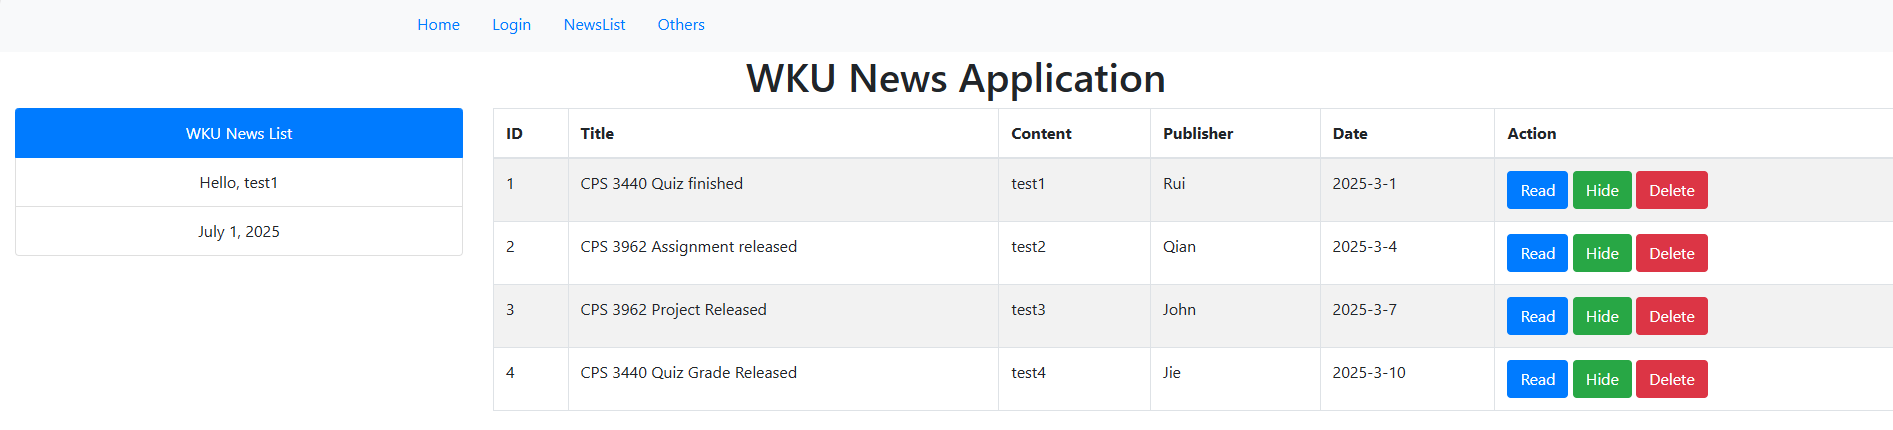

### Load data from a database

We can load wkunews from the database table (wkunews)

refer to:
https://docs.djangoproject.com/en/4.1/topics/db/queries/

Since the wkunews table in our current model, there are no publisher and post datetime info. We revise our model code as follows:

In [ ]:
class wkunews (models.Model):
    title = models.CharField(max_length=60)
    content = models.TextField()
    publisher = models.CharField(max_length=20, default="NA")
    timestamp = models.DateTimeField(auto_now=True)

Apply the model changes by typing the following two commands:

In [ ]:
E:\Django\HelloWorld> python manage.py makemigrations
E:\Django\HelloWorld> python manage.py migrate

Add a few news in the wkunews table

The success function in views.py is changed as follows:

In [ ]:
def success(request):
    today = datetime.datetime.now().date()
    username = request.session['username']  
    
    newslist=[]
    
    # select * from wkunews_wkunews
    #news = wkunews.objects.all()  # load the whole contents of the table
    
    # select * from wkunews_wkunews where date(timestamp) = "2025-07-01";
    news = wkunews.objects.filter(timestamp__date=today)
    
    dict={}
    for n in news:
        # We use a dict to pass the newslist to success.html, we have to change the current HTML template
        dict['id']=n.id
        dict['title'] = n.title
        dict['content'] = n.content
        dict['publisher'] = n.publisher
        dict['timestamp'] = n.timestamp
        newslist.append(dict)
    return render(request,"success.html",{"newslist":newslist,"date":today, "username":username})

We update the template of success.html with a navigation page. This time, we pass the newslist as a list of dictionaries.

In [ ]:
{% extends "base.html" %}

{% block body_block %}
<div class="container-fluid">
  <div class="row">
    <div class="col-3">
      <ul class="list-group">
       <li class="list-group-item active"> WKU News List</li>
       <li class="list-group-item">Hello, {{username}}</li>
       <li class="list-group-item">{{date}}</li>
      </ul>
    </div>

    <div class="col-9">
      <div class="table-responsive">
       <table id='table', class="table table-bordered table-striped table-hover">
        <thead>
         <tr>
          <th>ID</th>
          <th>Title</th>
          <th>Content</th>
          <th>Publisher</th>
          <th>Date</th>
          <th>Action</th>
         </tr>
        </thead>
        <tbody>
         {% for news in newslist %}
            <tr>
            <td>{{news.id }}</td>
            <td>{{news.title }}</td>
            <td>{{news.content }}</td>
            <td>{{news.publisher }}</td>
            <td>{{news.timestamp }}</td>
            <td>
                {% if news.id == id_read %}
                    <a href="http://127.0.0.1:8000/wkunews/read/{{ news.id }}" type="button" class="btn btn-outline-secondary" data-mdb-ripple-color="dark">Read</a>
               {% else %}
                    <a href="http://127.0.0.1:8000/wkunews/read/{{ news.id }}" type="button" class="btn btn-primary btn-xs ">Read</a>
               {% endif %}
               <a href="http://127.0.0.1:8000/wkunews/hide/{{ news.id }}" type="button" class="btn btn-success btn-xs ">Hide</a>
               <a href="http://127.0.0.1:8000/wkunews/delete/{{ news.id }}" type="button" class="btn btn-danger btn-xs ">Delete</a>
            </td>
          </tr>
        {% endfor %}
        </tbody>
      </table>

          <nav>
            <ul class="pagination">
              <li class="disabled"><a href="#" aria-label="Previous"><span aria-hidden="true">&laquo;</span></a></li>
              <li class="active"><a href="#">1 <span class="sr-only">(current)</span></a></li>
              <li class=""><a href="#">2 <span class="sr-only">(current)</span></a></li>
              <li class="acive"><a href="#">3 <span class="sr-only">(current)</span></a></li>
              <li class=""><a href="#">4 <span class="sr-only">(current)</span></a></li>
              <li class=""><a href="#">5 <span class="sr-only">(current)</span></a></li>
              <li><a href="#" aria-label="Next"><span aria-hidden="true">&laquo</span></a></li>
            </ul>
          </nav>

          <!--
          <meta http-equiv="refresh" content="3;url=https://www.w3cschool.cn/" >
            -->
    </div>
   </div>
</div>
    
{% endblock %}

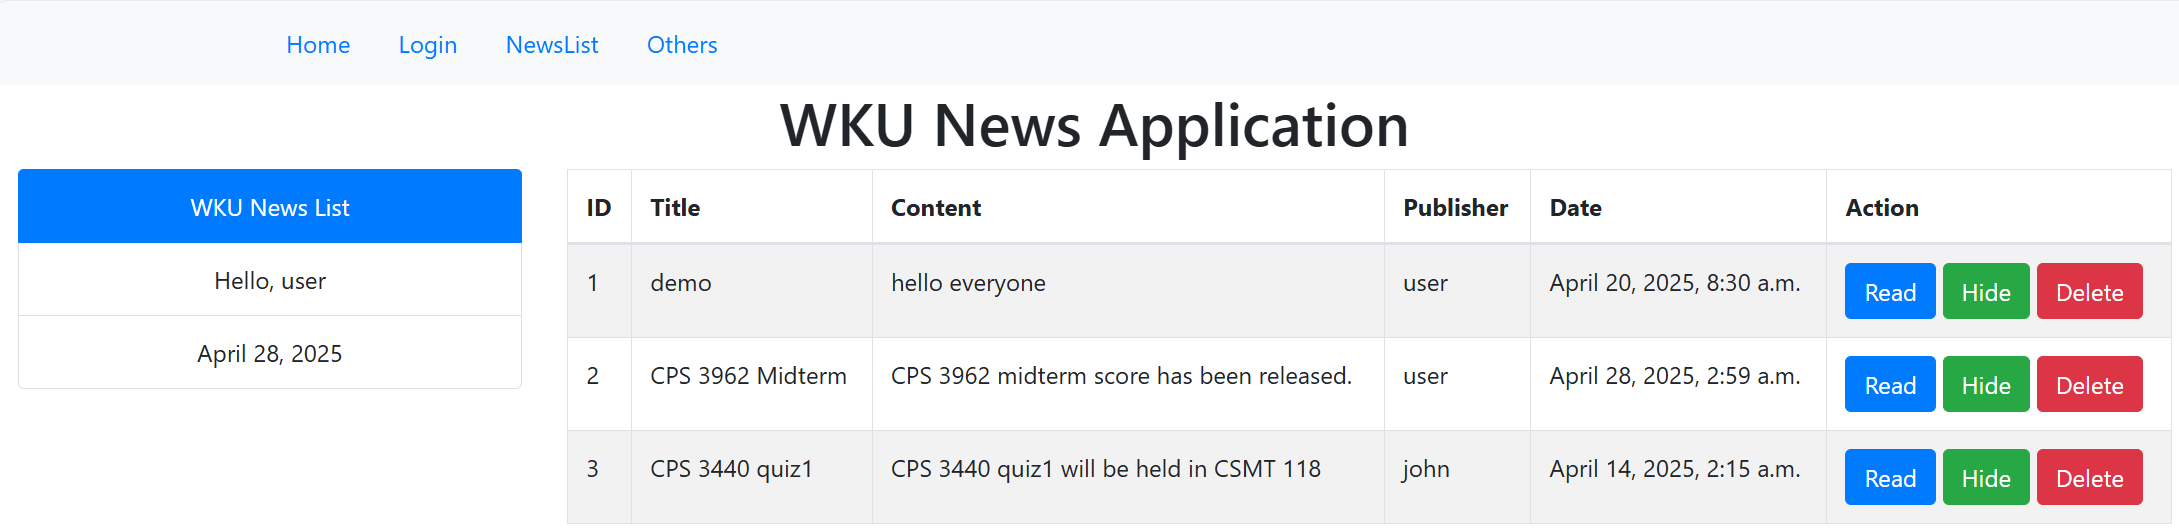

In [ ]:
def success(request):
    # read data from the database
    today = datetime.datetime.now().date()
    user_name = request.session['username']

    newslist=[]

    # Retrieving all objects
    #news = wkunews.objects.all()  # load the whole contents of the table

    # Retrieving specific objects with filters
    # Returns a new QuerySet containing objects that match the given lookup parameters.
    # select * from wkunews_wkunews where date(post_time) = "2022-12-06";
    #news = wkunews.objects.filter(publisher=username)
    #news = wkunews.objects.filter(post_time="2022-12-06 13:00:00")
    #news = wkunews.objects.filter(post_time__date="2022-12-06")
    #news = wkunews.objects.filter(post_time__date__lte="2022-12-06")   # __lt
    #news = wkunews.objects.filter(post_time__date__gte="2025-01-02")    # __gt

    news = wkunews.objects.filter(post_time__date=today)

    #news = wkunews.objects.filter(title__contains='test')

    #news = wkunews.objects.filter(post_time__date=today, publisher="john")
    #news = wkunews.objects.filter(post_time__date=today).filter(publisher="john")

    # Retrieving specific objects with exclude
    # Returns a new QuerySet containing objects that do not match the given lookup parameters.
    #news = wkunews.objects.exclude(post_time__date=today)

    dict={}
    for n in news:
        #newslist.append([n.id, n.title, n.content, n.publisher, n.timestamp])
        dict['id']=n.id
        dict['title'] = n.title
        dict['content'] = n.content
        dict['publisher'] = n.publisher
        dict['timestamp'] = n.timestamp
        newslist.append(dict)

    return render(request,"success.html",{"newslist":newslist,"date":today, "user_name":user_name})


## filter conditions

    __gt  >
    __gte >=
    __lt <
    __lte <=
    __in 
    __startswith 
    __istartswith    ignore case
    __endswith
    __iendswith     ignore case
    __range 
    __year        year of a date    
    __month       month of a date
    __day        day of a date
    __isnull
    __contains
    __icontains    ignore case
    __exact


You can install DB browser for SQLite to view database info. Here is the link: https://sqlitebrowser.org/dl/

## Extra Content

To handle those three buttons, we need to add paths in urls.py and corresponding functions in views.py.

In [ ]:
# urls.py
from django.urls import path

from . import views

urlpatterns = [
    path('', views.index),
    path('login', views.login, name='login'),
    path('success', views.success, name='success'),
    path('home', views.home),
    path('others', views.others),
    path('delete/<int:id>', views.delete, name='delete'),
    path('hide/<int:id>', views.hide, name='hide'),
    path('read/<int:id>', views.read, name='read'),
]

Add the following functions in views.py

In [ ]:
def news_newslist(news):
    newslist = []
    for n in news:
        dict1 = {'id': n.id, 'title': n.title, 'content': n.content, 'publisher': n.publisher, 'timestamp': n.timestamp}
        newslist.append(dict1)
    return newslist

def read_current_news(today):
    news = wkunews.objects.filter(timestamp__date=today)
    newslist = []
    for n in news:
        dict1 = {'id': n.id, 'title': n.title, 'content': n.content, 'publisher': n.publisher, 'timestamp': n.timestamp}
        newslist.append(dict1)
    return newslist

def read(request, id):
    if id > 0:
        today = datetime.datetime.now().date()
        user_name = request.session['username']
        newslist = read_current_news(today)

        #print("read: ", newslist)

        return render(request, "success_read.html",
                      {"newslist": newslist, "date": today, "user_name": user_name, "id_read": id})


def hide(request, id):
    if id>0:
        today = datetime.datetime.now().date()
        user_name = request.session['username']
        # use model to access database table
        #news = wkunews.objects.exclude(id=id).values()
        #newslist = news_newslist(news)
        news = wkunews.objects.filter(timestamp__date=today)
        newslist = []
        for n in news:
            if n.id != id:
                dict1 = {'id': n.id, 'title': n.title, 'content': n.content, 'publisher': n.publisher,
                         'timestamp': n.timestamp}
                newslist.append(dict1)

        #print("hide: ", newslist)

        return render(request, "success.html", {"newslist": newslist, "date": today, "user_name": user_name})


def delete(request, id):
    if id > 0:
        # use model to access database table
        user_name = request.session['username']
        today = datetime.datetime.now().date()
        newsinfo = wkunews.objects.get(id=id)
        if newsinfo.publisher == user_name:
            wkunews.objects.get(id=id).delete()  # delete this record

        newslist = read_current_news(today)
        return render(request, "success.html", {"newslist": newslist, "date": today, "user_name": user_name})


## Exercise

Add a register form, to allow new user to create an account

Add a new class in Forms.py

In [ ]:
class RegisterForm(forms.Form):
    username = forms.CharField(label='Username', max_length=25)
    password = forms.CharField(label='Password', max_length=30, widget=forms.PasswordInput)
    password2 = forms.CharField(label= 'Retype Password', max_length=30, widget=forms.PasswordInput)


Add a function register in views.py

In [ ]:
def register(request):
    if request.method == 'POST':
        username = ''
        passwd = ''
        passwd2 =''
        message = ''
        form = RegisterForm(request.POST or None)
        if form.is_valid():
            username = form.cleaned_data.get("username")
            passwd = form.cleaned_data.get("password")
            passwd2 = form.cleaned_data.get("password2")
            try:
                userinfo = user.objects.get(username=username)
                message = 'user already exists'
                return render(request, 'register.html', {'form': form, 'message': message})
            except:
                if passwd == passwd2:
                    #save new user to user
                    u = user(username=username, password=passwd, cellphone=0)
                    u.save()
                    message = "resister success"
                    return HttpResponseRedirect('login')
                else:
                    message = "password does not match, try again"
                return render(request, 'register.html', {'form': form, 'message': message})
    else:
        form = RegisterForm()
    return render(request, 'register.html', {'form': form})


Add form function in view.py

In [ ]:
def form(request):
    if request.method == 'POST':
        ID = 0
        firstname = ""
        lastname = ""
        email = ""
        user = ""
        password = ""

        form = RegisterForm(request.POST or None)
        if form.is_valid():
            ID = form.cleaned_data.get("ID")
            firstname = form.cleaned_data.get("firstname")
            lastname = form.cleaned_data.get("lastname")
            email = form.cleaned_data.get("email")
            user = form.cleaned_data.get("user")
            password = form.cleaned_data.get("password")

            args = (firstname, lastname, email, user, password)
            print(args)

            # save to database
            conn, cursor = connect_MySQL_sakila()
            if conn != 0:
                cursor = conn.cursor()
                # call a procedure to insert a staff record
                cursor.callproc('insert_staff', args)
                conn.commit()  # save data permanently
                cursor.close()
                conn.close()
                message = 'user registration success!'
            else:
                message = 'user registration failed!'

            return render(request, 'form.html', {'form':form, 'message':message})
    else:
        form = RegisterForm()
        message = 'something wrong, retry!'
        return render(request, 'form.html', {'form':form,  'message':message})



Add a new template: form.html

In [ ]:
{% extends "base.html" %}

{% block body_block %}

<div class="container">
    <h2>User Registration</h2>
    <form method="post">
        <div class="form-group">
            {% if message %}
                <div style="color:green" >{{ message }} user registeration success!</div>
            {% endif %}
            {% csrf_token %}
            {{ form.as_p }}
        </div>
    <button type="submit" class="btn btn-primary">user register</button>

    </form>
</div>


{% endblock %}

Add a new template for register: register.html

In [ ]:
{% extends "base.html" %}
{% block body_block %}
<div class="container">
    <h2>Register</h2>
    <form method="post">
        <div class="form-group">
            {% if message %}
                <div style="color:red" >{{ message }} Please try again!</div>
            {% endif %}
            {% csrf_token %}
            {{ form.as_p }}
        </div>
    <button type="submit" class="btn btn-primary">Create</button>

    </form>
</div>

{% endblock %}

add some path in urls.py

In [ ]:
# urls.py file
from django.urls import path

from . import views

urlpatterns = [
    path('', views.index),
    path('login',views.login),
    path('success', views.success),
    path('home', views.home),
    path('others', views.others),
    path('delete/<int:id>', views.delete, name='delete'),
    path('hide/<int:id>', views.hide, name='hide'),
    path('read/<int:id>', views.read, name='read'),
    path('form', views.form),
    path('register', views.register),
]

Add one item (register) in header.html template

In [ ]:
<nav class="navbar navbar-expand-lg navbar-light bg-light">
  <div class="container">

    <div>
      <ul class="nav">
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/home">Home</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/login">Login</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/register">Register</a>
        </li>
         <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/success">NewsList</a>
        </li>
        <li class="nav-item">
          <a class="nav-link" href="http://127.0.0.1:8000/wkunews/others">Others</a>
        </li>

      </ul>
    </div>
  </div>
</nav>